# Pipe leak prediction: compare four candidates and keep two

This notebook handles all cleaning, EDA, feature extraction, decision-tree feature
selection, encoding and imputation. The four candidate ideas are **adjusted age,
log length, material + surface, and the 75 m network leak rate**.

Material + surface is **one candidate group** containing multiple 0/1 columns.
It is included only if selected. Compare all six pairs and retain two groups.
Save the prepared data in `data/model_training_data.csv` for Notebook 06.
The model comparison uses **2025 and 2026**; no future-year predictions are produced.

## 1. Setup
Run cells from top to bottom. All workflow code is in the notebooks.

**Python environment:** choose the `Python (STAT 440 .venv)` kernel.

In [1]:
from pathlib import Path
from itertools import combinations
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components, dijkstra
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from IPython.display import display, Markdown

In [2]:
project_dir = Path.cwd()
if project_dir.name == "nds":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
fold_dir = data_dir / "model_folds"
results_dir = project_dir / "results" / "feature_selection"
fold_dir.mkdir(exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

random_seed = 440
prediction_years = [2025, 2026]
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})

## 2. Load, clean and explore the data
Join the first recorded leak year to the pipe inventory. Keep missing installation
dates missing until the imputation step. The original input CSVs stay unchanged.

In [3]:
pipes = pd.read_csv(data_dir / "pipes.csv").rename(columns={
    "Pipe ID": "pipe_id", "Lay date": "lay_date", "Material": "material",
    "Surface": "surface", "GPS x1": "x1", "GPS y1": "y1",
    "GPS x2": "x2", "GPS y2": "y2"
})
leaks = pd.read_csv(data_dir / "train.csv").rename(columns={
    "Pipe ID": "pipe_id", "Date": "leak_date"
})
pipes["lay_date"] = pd.to_datetime(pipes["lay_date"])
leaks["leak_date"] = pd.to_datetime(leaks["leak_date"])
first_leak = leaks.groupby("pipe_id")["leak_date"].min()
pipes["leak_year"] = pipes["pipe_id"].map(first_leak).dt.year
pipes["lay_year"] = pipes["lay_date"].dt.year
pipes["material"] = pipes["material"].fillna("unknown").str.strip().str.lower()
pipes["surface"] = pipes["surface"].fillna("unknown").str.strip().str.lower()

print(f"Pipes: {len(pipes):,}; recorded leak events: {len(leaks):,}")
display(pipes.head())

Pipes: 43,039; recorded leak events: 14,113


,pipe_id,lay_date,material,surface,x1,y1,x2,y2,leak_year,lay_year
0,P01001,1955-03-11,copper,grassland,6136.29,5020.97,6124.15,5020.97,NaN,1955.0
1,P01002,1971-09-19,cast iron,water,6512.35,4147.58,6536.59,4201.94,2023.0,1971.0
2,P01003,1971-09-18,cast iron,water,6536.59,4201.94,6518.42,4201.93,2024.0,1971.0
3,P01004,1982-05-22,cast iron,structure,2836.68,3377.95,2848.80,3405.12,NaN,1982.0
4,P01005,1971-07-03,cast iron,water,5117.28,4272.91,5126.37,4297.16,2024.0,1971.0


In [4]:
data_checks = pd.Series({
    "Duplicate pipe IDs": pipes["pipe_id"].duplicated().sum(),
    "Leak IDs absent from inventory": (~leaks["pipe_id"].isin(pipes["pipe_id"])).sum(),
    "Pipes with missing installation date": pipes["lay_date"].isna().sum(),
    "Pipes with multiple recorded leaks": (leaks.groupby("pipe_id").size() > 1).sum()
})
display(data_checks.to_frame("Count"))
display(pipes.isna().sum().to_frame("Missing values"))

,Count
Duplicate pipe IDs,0
Leak IDs absent from inventory,0
Pipes with missing installation date,15
Pipes with multiple recorded leaks,0


,Missing values
pipe_id,0
lay_date,15
material,0
surface,0
x1,0
y1,0
x2,0
y2,0
leak_year,28926
lay_year,15


### Material mix and annual events
Inspect the inventory and event counts before making annual training rows.

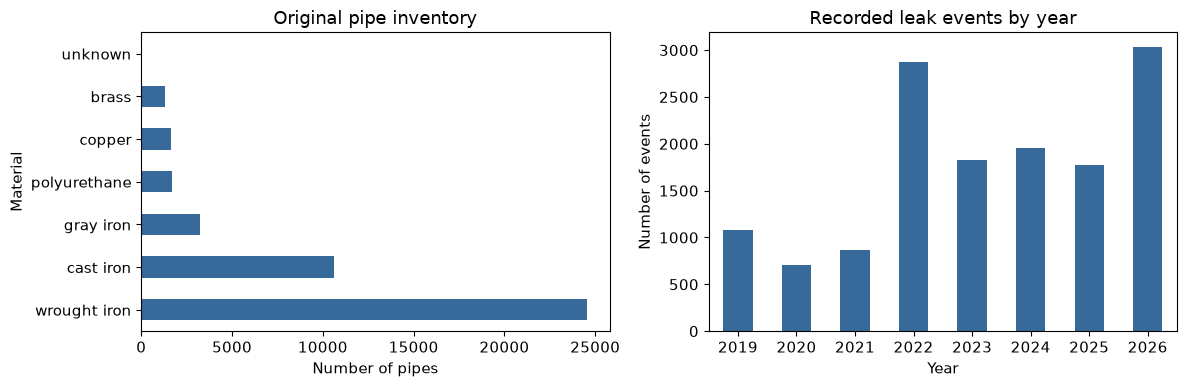

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pipes["material"].value_counts().plot.barh(ax=axes[0], color="#37699a")
axes[0].set(title="Original pipe inventory", xlabel="Number of pipes", ylabel="Material")
annual_events = leaks.groupby(leaks["leak_date"].dt.year).size()
annual_events.plot.bar(ax=axes[1], color="#37699a", rot=0)
axes[1].set(title="Recorded leak events by year", xlabel="Year", ylabel="Number of events")
plt.tight_layout()
plt.show()

### Pipe length and location
Coordinates are treated as metres. Calculate straight-line length and midpoint.

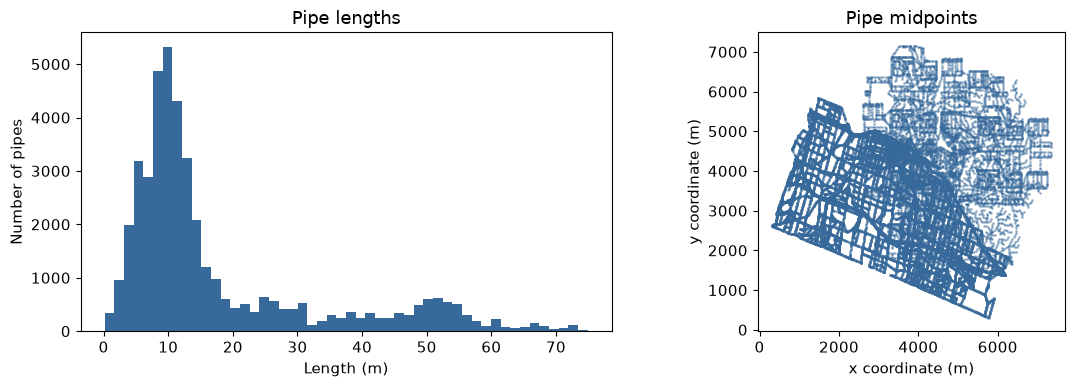

In [6]:
pipes["length_m"] = np.hypot(pipes["x2"] - pipes["x1"], pipes["y2"] - pipes["y1"])
midpoints = pipes[["x1", "y1"]].to_numpy() / 2 + pipes[["x2", "y2"]].to_numpy() / 2

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(pipes["length_m"], bins=50, color="#37699a")
axes[0].set(title="Pipe lengths", xlabel="Length (m)", ylabel="Number of pipes")
axes[1].scatter(midpoints[:, 0], midpoints[:, 1], s=1, color="#37699a", alpha=0.4)
axes[1].set(title="Pipe midpoints", xlabel="x coordinate (m)", ylabel="y coordinate (m)")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.show()

## 3. Extract the four candidate groups

| Candidate | Meaning |
|---|---|
| `adjusted_age` | Calendar age plus the inherited 0.4-per-year adjustment |
| `log_length` | log(1 + length in metres) |
| `material_surface` | Original material and surface, encoded as 0/1 columns |
| `network_rate_75m` | Smoothed previous-year leak rate within 75 m along connected pipes |

The 0.4 adjustment is inherited from earlier project development. Each historical
row uses only leak history available before the start of its year.

### Identify pipes at risk
Exclude polyurethane, known future installations and pipes treated as replaced
after a prior leak. A pipe leaking during year Y is at risk at the start of Y.

In [7]:
def at_risk(year):
    installed = pipes["lay_year"].isna() | (pipes["lay_year"] <= year)
    not_replaced = pipes["leak_year"].isna() | (pipes["leak_year"] >= year)
    not_polyurethane = pipes["material"] != "polyurethane"
    return (installed & not_replaced & not_polyurethane).to_numpy()

display(pd.DataFrame({
    "Year": range(2020, 2027),
    "Pipes at risk": [at_risk(year).sum() for year in range(2020, 2027)]
}))

,Year,Pipes at risk
0,2020,40283
1,2021,39580
2,2022,38714
3,2023,35840
4,2024,34014
5,2025,32059
6,2026,30286


### Calendar age and leap years
Use completed calendar years plus the fraction of the actual 365/366-day
anniversary interval. February 29 becomes February 28 in a non-leap year.

In [8]:
def calendar_age(installation_date, year):
    if pd.isna(installation_date):
        return np.nan
    forecast_date = pd.Timestamp(year=year, month=1, day=1)
    completed_years = year - installation_date.year
    anniversary = installation_date + pd.DateOffset(years=completed_years)
    if anniversary > forecast_date:
        completed_years -= 1
        anniversary = installation_date + pd.DateOffset(years=completed_years)
    next_anniversary = installation_date + pd.DateOffset(years=completed_years + 1)
    fraction = (forecast_date - anniversary).days / (next_anniversary - anniversary).days
    return completed_years + fraction

display(pd.DataFrame({
    "Forecast year": [2020, 2024, 2025],
    "Days in year": [366 if calendar.isleap(year) else 365 for year in [2020, 2024, 2025]],
    "Age of pipe laid 2019-01-01": [calendar_age(pd.Timestamp("2019-01-01"), year)
                                  for year in [2020, 2024, 2025]]
}))

,Forecast year,Days in year,Age of pipe laid 2019-01-01
0,2020,366,1.0
1,2024,366,5.0
2,2025,365,6.0


### Find neighbours along connected pipes
This is the spatial setup for the network-rate candidate. Group endpoints within
0.04 m into junctions, connect midpoint nodes to those junctions, and measure
short routes along the network. Interior crossings are not assumed to connect.
The small margin around 75 m preserves the existing float32 distance cutoff.

In [9]:
# 1. Group endpoints into junctions.
number_of_pipes = len(pipes)
endpoint_coordinates = np.vstack([
    pipes[["x1", "y1"]].to_numpy(), pipes[["x2", "y2"]].to_numpy()
])
endpoint_pairs = cKDTree(endpoint_coordinates).query_pairs(0.04, output_type="ndarray")
endpoint_links = sparse.csr_matrix(
    (np.ones(2 * len(endpoint_pairs)),
     (np.concatenate([endpoint_pairs[:, 0], endpoint_pairs[:, 1]]),
      np.concatenate([endpoint_pairs[:, 1], endpoint_pairs[:, 0]]))),
    shape=(2 * number_of_pipes, 2 * number_of_pipes)
)
number_of_junctions, junction_ids = connected_components(endpoint_links)
print(f"Inferred junctions: {number_of_junctions:,}")

Inferred junctions: 42,570


In [10]:
# 2. Connect each midpoint to its two junctions, weighted by half the pipe length.
midpoint_ids = number_of_junctions + np.arange(number_of_pipes)
edge_start = junction_ids
edge_end = np.concatenate([midpoint_ids, midpoint_ids])
half_lengths = np.tile(pipes["length_m"].to_numpy() / 2, 2)
number_of_nodes = number_of_junctions + number_of_pipes

pipe_graph = sparse.csr_matrix(
    (np.concatenate([half_lengths, half_lengths]),
     (np.concatenate([edge_start, edge_end]), np.concatenate([edge_end, edge_start]))),
    shape=(number_of_nodes, number_of_nodes)
)
print(f"Graph nodes: {number_of_nodes:,}")

Graph nodes: 85,609


In [11]:
# 3. Find nearby pipes in small batches to limit memory use.
row_parts, column_parts, distance_parts = [], [], []
for start in range(0, number_of_pipes, 96):
    stop = min(start + 96, number_of_pipes)
    distances = dijkstra(pipe_graph, directed=False,
                         indices=midpoint_ids[start:stop], limit=75.01)[:, midpoint_ids]
    distances[np.arange(stop - start), np.arange(start, stop)] = np.inf
    nearby_rows, nearby_columns = np.where(np.isfinite(distances))
    row_parts.append(nearby_rows + start)
    column_parts.append(nearby_columns)
    distance_parts.append(distances[nearby_rows, nearby_columns].astype("float32"))

network_rows = np.concatenate(row_parts)
network_columns = np.concatenate(column_parts)
network_distances = np.concatenate(distance_parts)

In [12]:
keep = network_distances <= 75
network_neighbours = sparse.csr_matrix(
    (np.ones(keep.sum(), dtype="float32"), (network_rows[keep], network_columns[keep])),
    shape=(number_of_pipes, number_of_pipes)
)
print("Mean 75 m network neighbours:", round(network_neighbours.getnnz(axis=1).mean(), 1))

Mean 75 m network neighbours: 17.6


### Encode material and surface
The category vocabulary comes from the known physical inventory, without leak
outcomes. All category columns are selected or removed together as one group.

In [13]:
category_data = pd.get_dummies(pipes[["material", "surface"]], dtype=int)
categorical_columns = category_data.columns.tolist()
display(category_data.head())

,material_brass,material_cast iron,material_copper,material_gray iron,material_polyurethane,material_unknown,material_wrought iron,surface_farmland,surface_grassland,surface_road,surface_structure,surface_swamp,surface_water
0,0,0,1,0,0,0,0,0,1,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,1
2,0,1,0,0,0,0,0,0,0,0,0,0,1
3,0,1,0,0,0,0,0,0,0,0,1,0,0
4,0,1,0,0,0,0,0,0,0,0,0,0,1


In [14]:
feature_groups = {
    "adjusted_age": ["adjusted_age"],
    "log_length": ["log_length"],
    "material_surface": categorical_columns,
    "network_rate_75m": ["network_rate_75m"]
}
candidate_names = list(feature_groups)

def predictor_columns(groups):
    return [column for group in groups for column in feature_groups[group]]

### Calculate the previous-year network rate
Smooth the rate as (nearby leaks + 10 × overall past rate) / (nearby at-risk pipes + 10).
Matrix multiplication adds values over neighbours. A pipe is not its own neighbour.

In [15]:
def network_rate(year):
    exposure = at_risk(year - 1).astype(float)
    events = (pipes["leak_year"] == year - 1).to_numpy(float)
    overall_rate = events.sum() / max(exposure.sum(), 1)
    nearby_events = network_neighbours @ events
    nearby_exposure = network_neighbours @ exposure
    return (nearby_events + 10 * overall_rate) / (nearby_exposure + 10)

### Create one labelled row per pipe and year
For each at-risk pipe, target 1 means a leak during that year and 0 means no leak.
IDs and year identify rows; neither is a predictor.

In [16]:
yearly_tables = []
for year in range(2020, 2027):
    year_data = pd.concat([pipes[["pipe_id"]], category_data], axis=1)
    age = pipes["lay_date"].apply(lambda date: calendar_age(date, year))
    year_data["adjusted_age"] = age + 0.4 * (year - 2020)
    year_data["log_length"] = np.log1p(pipes["length_m"])
    year_data["network_rate_75m"] = network_rate(year)
    year_data["year"] = year
    year_data["target"] = (pipes["leak_year"] == year).astype(int)
    yearly_tables.append(year_data.loc[at_risk(year)])
model_data = pd.concat(yearly_tables, ignore_index=True)
print(f"Pipe-year rows: {len(model_data):,}; candidate groups: {len(candidate_names)}")
display(model_data[["pipe_id", "year", "target", "adjusted_age", "log_length", "network_rate_75m"]].head().T)

Pipe-year rows: 250,776; candidate groups: 4


,0,1,2,3,4
pipe_id,P01001,P01002,P01003,P01004,P01005
year,2020,2020,2020,2020,2020
target,0,0,0,0,0
adjusted_age,64.808743,48.284153,48.286885,37.612022,48.497268
log_length,2.575661,4.102968,2.953347,3.425912,3.292041
network_rate_75m,0.084042,0.021719,0.020049,0.023694,0.023694


### Annual leak rates
Use the number of at-risk pipes as the denominator, not the original inventory size.

,Pipes at risk,Leaks,Leak rate
year,,,
2020,40283,703,0.0175
2021,39580,866,0.0219
2022,38714,2874,0.0742
2023,35840,1826,0.0509
2024,34014,1955,0.0575
2025,32059,1773,0.0553
2026,30286,3038,0.1003


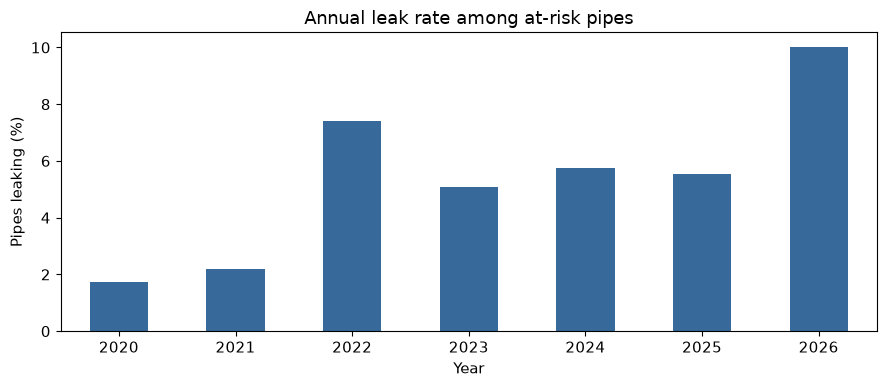

In [17]:
annual_summary = model_data.groupby("year")["target"].agg(["size", "sum", "mean"])
annual_summary.columns = ["Pipes at risk", "Leaks", "Leak rate"]
display(annual_summary.round(4))
ax = (100 * annual_summary["Leak rate"]).plot.bar(color="#37699a", rot=0)
ax.set(title="Annual leak rate among at-risk pipes", xlabel="Year", ylabel="Pipes leaking (%)")
plt.tight_layout()
plt.show()

## 4. Train decision trees and select two groups
Use maximum depth 5 and minimum leaf size 80. Fit medians only on training rows.
For evaluation year Y, select with fitting years 2020–Y−2 and validation Y−1.
For the complete training CSV, fit through 2025 and validate on 2026.

In [18]:
def score_features(training, validation, groups):
    columns = predictor_columns(groups)
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    x_train = imputer.fit_transform(training[columns])
    x_validation = imputer.transform(validation[columns])
    tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=80, random_state=random_seed)
    tree.fit(x_train, training["target"])
    probabilities = tree.predict_proba(x_validation)[:, 1]
    return {"roc_auc": roc_auc_score(validation["target"], probabilities),
            "average_precision": average_precision_score(validation["target"], probabilities)}

selection_training = model_data[model_data["year"] < 2026]
selection_validation = model_data[model_data["year"] == 2026]

### Inspect the four groups' tree importance
Sum split-based importance across the material/surface indicator columns to show
that candidate as one bar. The actual selection below uses validation ROC-AUC.

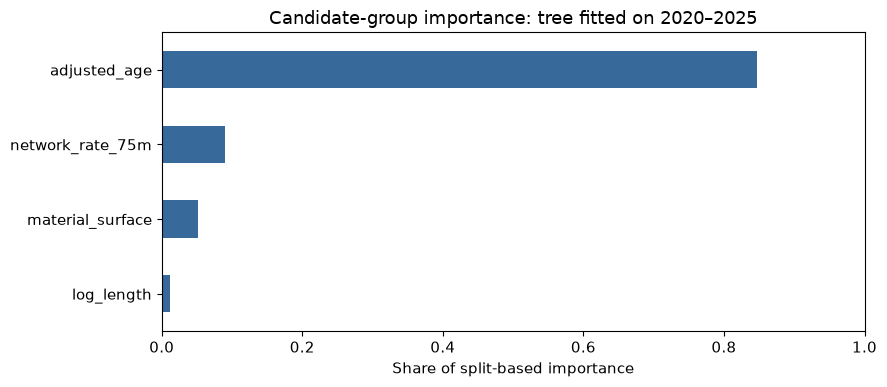

In [19]:
all_columns = predictor_columns(candidate_names)
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
x_train = imputer.fit_transform(selection_training[all_columns])
reference_tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=80, random_state=random_seed)
reference_tree.fit(x_train, selection_training["target"])
column_importance = pd.Series(reference_tree.feature_importances_, index=all_columns)
group_importance = pd.Series({name: column_importance[columns].sum()
                             for name, columns in feature_groups.items()})
ax = group_importance.sort_values().plot.barh(color="#37699a")
ax.set(title="Candidate-group importance: tree fitted on 2020–2025",
       xlabel="Share of split-based importance", ylabel="", xlim=(0, 1))
plt.tight_layout()
plt.show()

### Compare each candidate by itself
Each model uses only the named group. Material/surface is not automatically added
to the other candidates. Scores use 2026 validation rows.

,Candidate,roc_auc,average_precision
0,adjusted_age,0.8811,0.4286
3,network_rate_75m,0.5818,0.1536
1,log_length,0.5238,0.1080
2,material_surface,0.4102,0.0871


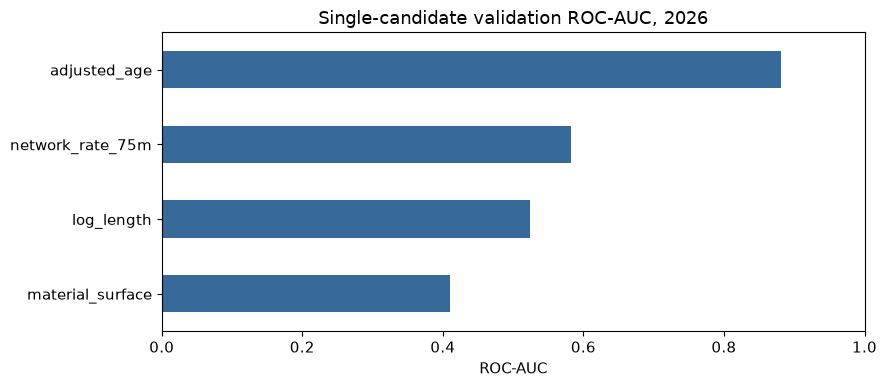

In [20]:
single_rows = []
for group in candidate_names:
    scores = score_features(selection_training, selection_validation, [group])
    single_rows.append({"Candidate": group, **scores})
single_results = pd.DataFrame(single_rows).sort_values("roc_auc", ascending=False)
display(single_results.round(4))
ax = single_results.plot.barh(x="Candidate", y="roc_auc", legend=False, color="#37699a")
ax.set(title="Single-candidate validation ROC-AUC, 2026", xlabel="ROC-AUC", ylabel="", xlim=(0, 1))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Test all six pairs
Choose the highest validation ROC-AUC, then average precision to break a tie.
Repeat for the 2025/2026 evaluations and for the full-data refit.

In [21]:
def choose_pair(training, validation):
    rows = []
    for pair in combinations(candidate_names, 2):
        scores = score_features(training, validation, list(pair))
        rows.append({"groups": list(pair), **scores})
    return max(rows, key=lambda row: (row["roc_auc"], row["average_precision"])), rows

selected_groups = {}
selection_rows = []
for year in prediction_years:
    training = model_data[model_data["year"] < year - 1]
    validation = model_data[model_data["year"] == year - 1]
    best, rows = choose_pair(training, validation)
    selected_groups[year] = best["groups"]
    selection_rows.extend({"Use": str(year), **row} for row in rows)

best_full, full_rows = choose_pair(selection_training, selection_validation)
final_groups = best_full["groups"]
selection_rows.extend({"Use": "Full training data", **row} for row in full_rows)
selected_table = pd.DataFrame([
    {"Use": str(year), "Group 1": groups[0], "Group 2": groups[1]}
    for year, groups in selected_groups.items()
] + [{"Use": "Full training data", "Group 1": final_groups[0], "Group 2": final_groups[1]}])
display(selected_table)
display(pd.DataFrame(full_rows).sort_values("roc_auc", ascending=False).round(4))

,Use,Group 1,Group 2
0,2025,adjusted_age,material_surface
1,2026,adjusted_age,network_rate_75m
2,Full training data,adjusted_age,network_rate_75m


,groups,roc_auc,average_precision
2,"[adjusted_age, network_rate_75m]",0.8893,0.4359
0,"[adjusted_age, log_length]",0.8844,0.4324
1,"[adjusted_age, material_surface]",0.8742,0.4244
4,"[log_length, network_rate_75m]",0.5836,0.1502
5,"[material_surface, network_rate_75m]",0.5109,0.1363
3,"[log_length, material_surface]",0.4648,0.0934


### Check whether each selected group adds value
Compare the full pair with one group removed, using the same 2026 validation data.

In [22]:
full_auc = score_features(selection_training, selection_validation, final_groups)["roc_auc"]
removal_rows = []
for removed in final_groups:
    remaining = [group for group in final_groups if group != removed]
    reduced_auc = score_features(selection_training, selection_validation, remaining)["roc_auc"]
    removal_rows.append({"Removed group": removed, "AUC without group": reduced_auc,
                         "AUC drop": full_auc - reduced_auc})
display(pd.DataFrame(removal_rows).round(5))

,Removed group,AUC without group,AUC drop
0,adjusted_age,0.58183,0.30750
1,network_rate_75m,0.88112,0.00821


### Evaluate the reference tree in 2025 and 2026
Refit using all earlier years. These evaluation outcomes do not choose their own features.

In [23]:
reference_rows = []
for year in prediction_years:
    training = model_data[model_data["year"] < year]
    testing = model_data[model_data["year"] == year]
    for label, groups in {"Selected pair": selected_groups[year], "All four": candidate_names}.items():
        reference_rows.append({"year": year, "Inputs": label, **score_features(training, testing, groups)})
reference_results = pd.DataFrame(reference_rows)
display(reference_results.round(4))

,year,Inputs,roc_auc,average_precision
0,2025,Selected pair,0.7923,0.3480
1,2025,All four,0.8286,0.3548
2,2026,Selected pair,0.8893,0.4359
3,2026,All four,0.8899,0.4361


## 5. Prepare the numerical model inputs
Use only columns from the selected two groups. Fit medians on each training
table and apply them to the matching validation/test table. All preprocessing
happens here; Notebook 06 only reads the prepared CSVs.

In [24]:
def prepare_tables(training, testing, groups):
    columns = predictor_columns(groups)
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    train_values = imputer.fit_transform(training[columns])
    test_values = imputer.transform(testing[columns])
    metadata = ["pipe_id", "year", "target"]
    prepared_train = training[metadata].reset_index(drop=True).copy()
    prepared_test = testing[metadata].reset_index(drop=True).copy()
    prepared_train[columns] = train_values
    prepared_test[columns] = test_values
    return prepared_train, prepared_test

## 6. Save CSVs for model training
Save the two annual evaluation folds and a final complete training CSV containing
all labelled 2020–2026 rows. The `full_training` tuning pair uses 2020–2025/2026.
It supports refitting the winning family on all available labels, without future predictions.

In [25]:
for year in prediction_years:
    training = model_data[model_data["year"] < year]
    testing = model_data[model_data["year"] == year]
    inner = training[training["year"] < year - 1]
    validation = training[training["year"] == year - 1]
    prepared_inner, prepared_validation = prepare_tables(inner, validation, selected_groups[year])
    prepared_train, prepared_test = prepare_tables(training, testing, selected_groups[year])
    year_dir = fold_dir / str(year)
    year_dir.mkdir(exist_ok=True)
    for name, frame in [("inner_train", prepared_inner), ("validation", prepared_validation),
                        ("train", prepared_train), ("test", prepared_test)]:
        frame.to_csv(year_dir / f"{name}.csv.gz", index=False)

full_dir = fold_dir / "full_training"
full_dir.mkdir(exist_ok=True)
inner, validation = prepare_tables(selection_training, selection_validation, final_groups)
inner.to_csv(full_dir / "inner_train.csv.gz", index=False)
validation.to_csv(full_dir / "validation.csv.gz", index=False)

In [26]:
final_columns = predictor_columns(final_groups)
full_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
prepared_full = model_data[["pipe_id", "year", "target"]].copy()
prepared_full[final_columns] = full_imputer.fit_transform(model_data[final_columns])
prepared_full.to_csv(data_dir / "model_training_data.csv", index=False)
selected_table.to_csv(results_dir / "selected_features.csv", index=False)
pd.DataFrame(selection_rows).to_csv(results_dir / "feature_combinations.csv", index=False)
reference_results.to_csv(results_dir / "reference_scores.csv", index=False)

print("Saved:", data_dir / "model_training_data.csv")
print("Selected groups:", final_groups)
print(f"Rows: {len(prepared_full):,}; numerical input columns: {len(final_columns)}")
print("Missing predictor values:", prepared_full[final_columns].isna().sum().sum())
display(prepared_full.head().T)

Saved: /Users/simondoan/Documents/SFU/STAT 440/Project/P1/data/model_training_data.csv
Selected groups: ['adjusted_age', 'network_rate_75m']
Rows: 250,776; numerical input columns: 2
Missing predictor values: 0


,0,1,2,3,4
pipe_id,P01001,P01002,P01003,P01004,P01005
year,2020,2020,2020,2020,2020
target,0,0,0,0,0
adjusted_age,64.808743,48.284153,48.286885,37.612022,48.497268
network_rate_75m,0.084042,0.021719,0.020049,0.023694,0.023694
